# **Revisión del modelado de AFG2**

En este notebook complementaremos el análisis de `19-jss-modelos.ipynb`, preparado por Jason. Nos concentraremos en tres aspectos que vale la pena mirar con más detalle antes de cerrar el modelado de la semana 4:

1. ¿Cuánto mejora la extracción al pasar de `qwen3:8b` a `qwen3.6:27b` y qué ocurre con el tiempo de ejecución?
2. ¿En qué etapa se originaron las fallas observadas en la condición C2?
3. ¿Qué controles necesitamos revisar para comparar C1 y C2 de manera válida?

Usaremos los **resultados que Jason ya obtuvo**, no haremos pruebas nuevas con los modelos. Copié los valores publicados en las secciones 5.3, 5.6, 7.2–7.5, 8.3 y 11 para que este archivo pueda ejecutarse por separado, sin depender del repositorio ni de Ollama. Las tablas y los gráficos se calculan aquí a partir de esos datos.

Esta copia nos sirve para analizar y discutir las mejoras. Si decidimos incorporarlas al notebook original, conectaremos los cálculos con sus variables y archivos de resultados para evitar mantener cifras duplicadas. Por ahora, **no modificaremos el notebook de Jason ni el diseño del experimento**.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.precision", 3)

def gm_mostrar(texto):
    display(Markdown(texto))

print("Complemento autónomo preparado: pandas", pd.__version__, "· matplotlib", plt.matplotlib.__version__)

Complemento autónomo preparado: pandas 2.2.3 · matplotlib 3.10.8


# **1. Calidad de extracción y tiempo de ejecución**

En la sección 5.3, Jason comparó `qwen3:8b` y `qwen3.6:27b` mediante una prueba confirmatoria de **15 corridas nuevas por modelo y serie**, utilizando ES2015 y TS3009. Los resultados se alinearon con un umbral de τ = 0,60.

Reuniremos en una misma tabla el F1, el *recall*, las fallas registradas y el tiempo de extracción. Así podremos revisar no solo si el modelo de mayor tamaño entrega mejores resultados, sino cuánto más demora en esta etapa del procesamiento.

Los valores de calidad proceden de la tabla confirmatoria de la sección 5.3; los tiempos con un decimal, de la sección 8.3. Estos segundos corresponden al paso de extracción de decisiones y **no al tiempo total de C2**. Tampoco representan costos monetarios.

In [2]:
# Uso los valores publicados por Jason en las secciones 5.3 y 8.3.
GM_CONFIRMATORIA = pd.DataFrame([
    {"serie":"ES2015", "modelo":"qwen3:8b",    "f1":0.289, "recall":0.474, "segundos":165.7, "fallas":1, "reuniones":60, "decisiones_reunion":15.4},
    {"serie":"ES2015", "modelo":"qwen3.6:27b", "f1":0.470, "recall":0.575, "segundos":597.6, "fallas":0, "reuniones":60, "decisiones_reunion":9.8},
    {"serie":"TS3009", "modelo":"qwen3:8b",    "f1":0.303, "recall":0.646, "segundos":488.8, "fallas":6, "reuniones":60, "decisiones_reunion":21.3},
    {"serie":"TS3009", "modelo":"qwen3.6:27b", "f1":0.474, "recall":0.818, "segundos":894.7, "fallas":4, "reuniones":60, "decisiones_reunion":15.9},
])

assert not GM_CONFIRMATORIA.duplicated(["serie", "modelo"]).any()
display(GM_CONFIRMATORIA.set_index(["serie", "modelo"]).round(3))

f1  recall  ...  reuniones  decisiones_reunion
serie  modelo                      ...                               
ES2015 qwen3:8b     0.289   0.474  ...         60                15.4
       qwen3.6:27b  0.470   0.575  ...         60                 9.8
TS3009 qwen3:8b     0.303   0.646  ...         60                21.3
       qwen3.6:27b  0.474   0.818  ...         60                15.9

[4 rows x 6 columns]

In [3]:
# Comparo ambos modelos dentro de cada serie.
GM_BASE = GM_CONFIRMATORIA.loc[GM_CONFIRMATORIA.modelo == "qwen3:8b"].set_index("serie")
GM_ALT = GM_CONFIRMATORIA.loc[GM_CONFIRMATORIA.modelo == "qwen3.6:27b"].set_index("serie")

GM_COMPARACION = pd.DataFrame(index=GM_BASE.index)
GM_COMPARACION["F1 base"] = GM_BASE.f1
GM_COMPARACION["F1 candidato"] = GM_ALT.f1
GM_COMPARACION["Δ F1 (aprox.)"] = GM_ALT.f1 - GM_BASE.f1
GM_COMPARACION["Δ recall (aprox.)"] = GM_ALT.recall - GM_BASE.recall
GM_COMPARACION["tiempo base (s)"] = GM_BASE.segundos
GM_COMPARACION["tiempo candidato (s)"] = GM_ALT.segundos
GM_COMPARACION["multiplicador de tiempo"] = GM_ALT.segundos / GM_BASE.segundos
GM_COMPARACION["fallas base /60"] = GM_BASE.fallas
GM_COMPARACION["fallas candidato /60"] = GM_ALT.fallas

# Las diferencias son aproximadas porque los resultados originales están redondeados.
display(GM_COMPARACION.round(3))

for serie, fila in GM_COMPARACION.iterrows():
    print(f"{serie}: Δ F1 ≈ {fila['Δ F1 (aprox.)']:.3f}; "
          f"Δ recall ≈ {fila['Δ recall (aprox.)']:.3f}; "
          f"tiempo ×{fila['multiplicador de tiempo']:.2f}")

,F1 base,F1 candidato,Δ F1 (aprox.),Δ recall (aprox.),tiempo base (s),tiempo candidato (s),multiplicador de tiempo,fallas base /60,fallas candidato /60
serie,,,,,,,,,
ES2015,0.289,0.470,0.181,0.101,165.7,597.6,3.607,1,0
TS3009,0.303,0.474,0.171,0.172,488.8,894.7,1.830,6,4


ES2015: Δ F1 ≈ 0.181; Δ recall ≈ 0.101; tiempo ×3.61
TS3009: Δ F1 ≈ 0.171; Δ recall ≈ 0.172; tiempo ×1.83


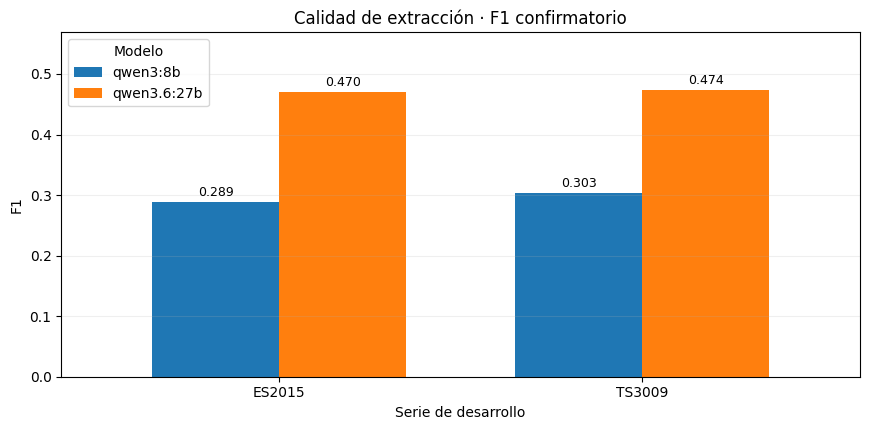

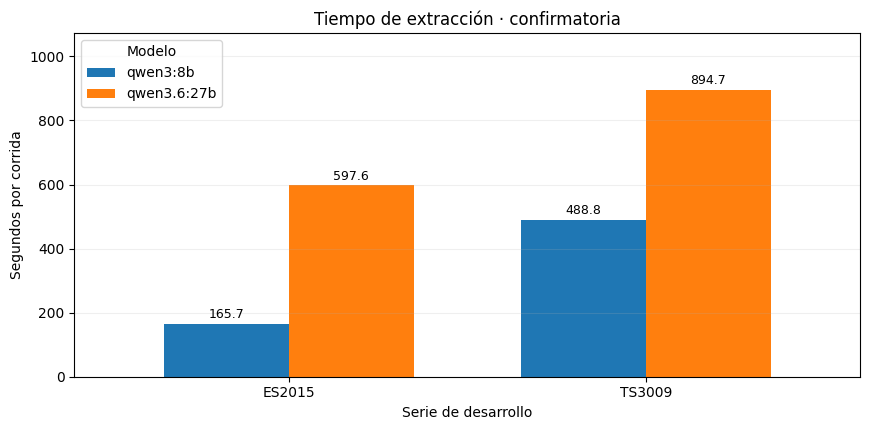

In [4]:
# Separo F1 y tiempo para no mezclar escalas.
for metrica, titulo, ylabel, nombre in [
    ("f1", "Calidad de extracción · F1 confirmatorio", "F1", "F1"),
    ("segundos", "Tiempo de extracción · confirmatoria", "Segundos por corrida", "tiempo"),
]:
    pivote = GM_CONFIRMATORIA.pivot(index="serie", columns="modelo", values=metrica)
    fig, ax = plt.subplots(figsize=(8.8, 4.4))
    pivote[["qwen3:8b", "qwen3.6:27b"]].plot(kind="bar", ax=ax, rot=0, width=0.7)
    ax.set_title(titulo)
    ax.set_xlabel("Serie de desarrollo")
    ax.set_ylabel(ylabel)
    ax.legend(title="Modelo")
    ax.grid(axis="y", alpha=0.2)
    for contenedor in ax.containers:
        ax.bar_label(contenedor, fmt="%.3f" if metrica == "f1" else "%.1f", padding=2, fontsize=9)
    ax.set_ylim(0, max(pivote.max()) * 1.20)
    plt.tight_layout()
    display(fig)
    plt.close(fig)

### **Resultado de la comparación**

`qwen3.6:27b` obtuvo un F1 mayor en ambas series. En ES2015 pasó de **0,289 a 0,470**; en TS3009, de **0,303 a 0,474**. El *recall* también aumentó y las corridas confirmatorias registraron menos reuniones fallidas con el modelo de 27B.

La diferencia aparece en el tiempo de procesamiento. En ES2015, el modelo de 27B demoró aproximadamente **3,6 veces** lo que tardó `qwen3:8b`. En TS3009, esa relación fue de **1,8 veces**. No conviene resumir ambos valores en un único multiplicador: estamos comparando series distintas y Jason advierte que el tiempo de `qwen3:8b` en TS3009 estuvo afectado por las reuniones fallidas.

Estas pruebas muestran una mejora de calidad acompañada de una mayor latencia. **No resuelven por sí solas cuál extractor debemos adoptar**: la regla de selección sigue siendo la definida para el experimento y la decisión permanece abierta en el issue #143. Tampoco contamos aquí con mediciones de RAM/VRAM, consumo energético, costos financieros o desempeño en el conjunto reservado de evaluación.

Para el video, creo que bastaría mostrar el cambio de F1 junto con el tiempo observado en cada serie. Esa comparación comunica mejor la decisión técnica que hablar de un «costo computacional» sin precisar qué medimos.

# **2. Dónde se están produciendo los errores de C2**

La condición C2 construye una base de conocimiento a partir de las reuniones. Cuando falla una respuesta, el problema puede haber ocurrido antes de la generación: durante la extracción de un hecho o al recuperar los objetos que contienen la evidencia.

En las **21 preguntas de desarrollo de ES2015**, Jason ejecutó una corrida de C1 y una de C2. Para este análisis revisaremos el estrato E1, que contiene **14 preguntas de hechos puntuales** por condición. C2 respondió correctamente cinco y falló en nueve.

El origen de esas nueve fallas ya fue examinado por Jason: **una atribución se realizó mediante una regla y ocho mediante revisión humana** (PR #177). Retomaremos esa clasificación para entender dónde se concentran los problemas, sin presentarla como una auditoría nueva ni extender sus conclusiones a otras series.

,preguntas,correctas,respuesta_incorrecta,abstencion_incorrecta,fallas,exactitud_pct,control_fallas
condicion,,,,,,,
C1 · RAG,14,10,1,3,4,71.4,True
C2 · compilada,14,5,5,4,9,35.7,True


,casos,interpretacion,porcentaje_de_las_9_fallas
etapa,,,
Recuperación,4,"La información estaba representada, pero no llegó al generador",44.4
Extracción,3,El objeto persistido omitió o distorsionó el hecho,33.3
Síntesis,2,La evidencia seleccionada no produjo la respuesta esperada,22.2


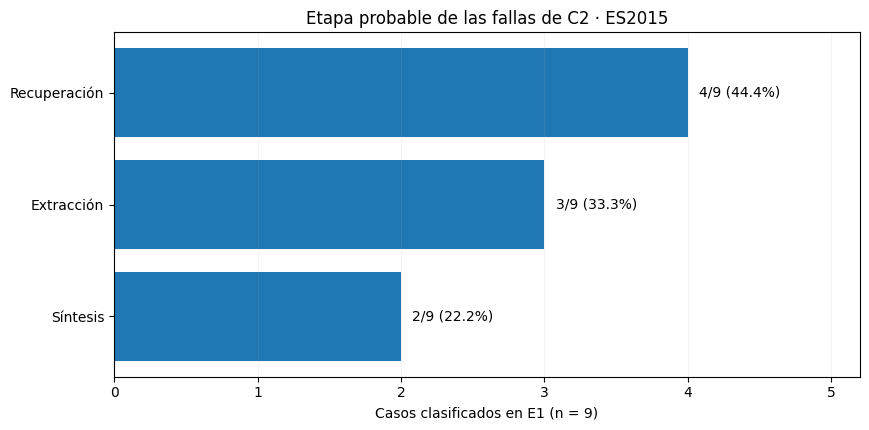

In [5]:
# Recupero los conteos de E1 que Jason documentó en las secciones 7.2–7.5.
GM_PREGUNTAS_E1 = pd.DataFrame([
    {"condicion":"C1 · RAG", "preguntas":14, "correctas":10, "respuesta_incorrecta":1, "abstencion_incorrecta":3},
    {"condicion":"C2 · compilada", "preguntas":14, "correctas":5, "respuesta_incorrecta":5, "abstencion_incorrecta":4},
])
GM_PREGUNTAS_E1["fallas"] = GM_PREGUNTAS_E1.preguntas - GM_PREGUNTAS_E1.correctas
GM_PREGUNTAS_E1["exactitud_pct"] = GM_PREGUNTAS_E1.correctas / GM_PREGUNTAS_E1.preguntas * 100
GM_PREGUNTAS_E1["control_fallas"] = (
    GM_PREGUNTAS_E1.respuesta_incorrecta + GM_PREGUNTAS_E1.abstencion_incorrecta
    == GM_PREGUNTAS_E1.fallas
)
display(GM_PREGUNTAS_E1.set_index("condicion").round(1))

GM_ETAPAS = pd.DataFrame([
    {"etapa":"Recuperación", "casos":4, "interpretacion":"La información estaba representada, pero no llegó al generador"},
    {"etapa":"Extracción", "casos":3, "interpretacion":"El objeto persistido omitió o distorsionó el hecho"},
    {"etapa":"Síntesis", "casos":2, "interpretacion":"La evidencia seleccionada no produjo la respuesta esperada"},
])
GM_ETAPAS["porcentaje_de_las_9_fallas"] = GM_ETAPAS.casos / GM_ETAPAS.casos.sum() * 100

display(GM_ETAPAS.set_index("etapa").round(1))

fig, ax = plt.subplots(figsize=(8.8, 4.4))
ax.barh(GM_ETAPAS.etapa, GM_ETAPAS.casos)
ax.invert_yaxis()
ax.set_xlim(0, 5.2)
ax.set_xticks(range(0,6))
ax.set_xlabel("Casos clasificados en E1 (n = 9)")
ax.set_title("Etapa probable de las fallas de C2 · ES2015")
for indice, fila in GM_ETAPAS.iterrows():
    ax.text(fila.casos + 0.08, indice, f"{fila.casos}/9 ({fila.porcentaje_de_las_9_fallas:.1f}%)", va="center")
ax.grid(axis="x", alpha=0.15)
plt.tight_layout()
display(fig)
plt.close(fig)

### **Qué muestra el desglose**

**Cuatro de las nueve fallas se atribuyeron a recuperación.** La información estaba representada en la base compilada, pero no llegó al contexto utilizado para responder. Jason documenta, por ejemplo, una recuperación sobre DVD/VCR cuando la consulta exigía identificar la exclusión del teletexto. Esto apunta a revisar la pertinencia de los objetos seleccionados. No permite asegurar todavía que cambiar el índice vaya a mejorar la exactitud.

**En otros tres casos, el problema se originó en la extracción.** El objeto guardado contenía una aproximación, omitía parte del hecho o registraba una propuesta descartada como decisión. Si ese contenido se recupera posteriormente, el buscador puede estar funcionando correctamente y aun así entregar información equivocada. Por eso importa volver a la transcripción y comprobar el estado de cada decisión.

**Las dos fallas restantes se atribuyeron a la síntesis de la respuesta.** El notebook también identifica resúmenes truncados y advierte sobre un posible falso negativo del juez en `q023`. Este último punto merece una revisión aparte: un error al calificar una respuesta no debe confundirse con un error del sistema que la generó. Para comprobar cada caso individual necesitaremos contrastar el diagnóstico con `oe4-etapa-e1.csv`, que no forma parte de este archivo autónomo.

En total, C2 acumuló **cinco respuestas equivocadas y cuatro abstenciones incorrectas** en E1. Que cuatro de las nueve fallas hayan ocurrido durante la recuperación es una pista útil para priorizar revisiones, pero la muestra es pequeña. No extrapolaremos esas proporciones a todo OpenKOS ni al estrato E3 de evolución, donde se probó solo una pregunta.

# **3. Comparabilidad entre C1 y C2**

Nuestra comparación busca establecer qué cambia cuando las respuestas se apoyan en **transcripciones recuperadas (C1)** o en una **base compilada automáticamente (C2)**. Para interpretar esa diferencia necesitamos comprobar que otras partes del proceso no introduzcan ventajas o restricciones adicionales.

El Notebook 19 deja documentados varios componentes compartidos, junto con algunas diferencias que todavía deben resolverse. Organizaremos esas observaciones en una tabla para distinguir qué está definido, qué necesitamos verificar durante la ejecución y qué sigue siendo una decisión del equipo.

La revisión se basa en las secciones 4, 5.6, 8.2, 9 y 11 de Jason. **No hemos inspeccionado las implementaciones actuales** ni comprobado todavía la equivalencia de las corridas finales.

In [6]:
# Ordeno los controles descritos en el Notebook 19 para revisarlos con el equipo.
GM_CONTROLES = pd.DataFrame([
    {"componente":"Generador", "situacion":"Compartido por diseño", "evidencia":"qwen3:8b en C1 y C2", "verificacion":"Confirmar el modelo y su digest en cada corrida"},
    {"componente":"Embeddings", "situacion":"Compartido por diseño", "evidencia":"bge-m3 según configuración declarada", "verificacion":"Registrar versión y huella de cada backend"},
    {"componente":"Contexto efectivo", "situacion":"Mecanismo documentado", "evidencia":"Recorte alineado con OpenKOS (ADR 0007)", "verificacion":"Comparar el texto efectivo entregado, no únicamente K o límite nominal"},
    {"componente":"Prompts de respuesta", "situacion":"Copiados con limitación", "evidencia":"C1 utiliza instrucciones copiadas de OpenKOS (ADR 0006)", "verificacion":"Revisar que las menciones a bundle/objetos no favorezcan a C2"},
    {"componente":"Suficiencia", "situacion":"Pendiente de homologación", "evidencia":"La rama principal puede verificar con otro modelo; 0.6.0 no tiene ese cambio", "verificacion":"Fijar versión o forzar qwen3:8b para suficiencia (issue #94)"},
    {"componente":"Fuentes originales en C2", "situacion":"Decisión abierta", "evidencia":"OpenKOS puede conservar y recuperar sources/ (issue #146)", "verificacion":"Establecer si C2 puede acceder a transcripciones originales"},
    {"componente":"Procedencia", "situacion":"Por verificar en corrida formal", "evidencia":"El notebook registra diferencias entre manifiestos de desarrollo", "verificacion":"Registrar versiones, commits, modelos y configuraciones congeladas"},
])
display(GM_CONTROLES.set_index("componente"))

,situacion,evidencia,verificacion
componente,,,
Generador,Compartido por diseño,qwen3:8b en C1 y C2,Confirmar el modelo y su digest en cada corrida
Embeddings,Compartido por diseño,bge-m3 según configuración declarada,Registrar versión y huella de cada backend
Contexto efectivo,Mecanismo documentado,Recorte alineado con OpenKOS (ADR 0007),"Comparar el texto efectivo entregado, no únicamente K o límite nominal"
Prompts de respuesta,Copiados con limitación,C1 utiliza instrucciones copiadas de OpenKOS (ADR 0006),Revisar que las menciones a bundle/objetos no favorezcan a C2
Suficiencia,Pendiente de homologación,La rama principal puede verificar con otro modelo; 0.6.0 no tiene ese cambio,Fijar versión o forzar qwen3:8b para suficiencia (issue #94)
Fuentes originales en C2,Decisión abierta,OpenKOS puede conservar y recuperar sources/ (issue #146),Establecer si C2 puede acceder a transcripciones originales
Procedencia,Por verificar en corrida formal,El notebook registra diferencias entre manifiestos de desarrollo,"Registrar versiones, commits, modelos y configuraciones congeladas"


### **Qué debemos comprobar antes de la evaluación**

El generador y el modelo de *embeddings* están declarados como compartidos entre C1 y C2. Eso ayuda a controlar el experimento, pero no basta para atribuir cualquier diferencia de respuestas exclusivamente a la representación del conocimiento.

Hay dos puntos especialmente sensibles. La **verificación de suficiencia** puede modificar cuándo se responde y cuándo se produce una abstención, incluso si la evidencia disponible es parecida. Además, si C2 puede consultar archivos originales en `sources/`, el sistema no estaría operando únicamente sobre los objetos compilados. Jason ya registró ambos asuntos en los issues **#94** y **#146**.

Yo mantendría esos puntos visibles hasta que se fijen las versiones y configuraciones de las corridas finales. Con la evidencia actual podemos explicar **qué controles están previstos**, pero todavía no afirmar que C1 y C2 se diferencian solamente por la representación consultada.

# **4. Revisión de consistencia**

Antes de compartir el complemento comprobaré que las cifras copiadas y los cálculos derivados sean coherentes entre sí: dos modelos en dos series, nueve fallas de C2 en E1 y siete aspectos de control experimental.

Esta revisión **no reemplaza la ejecución de los modelos ni la comprobación de las anotaciones humanas**. Solo verifica los cálculos de este notebook. Los casos individuales y las versiones de cada componente deberán cotejarse con los archivos del repositorio.

In [7]:
# Compruebo las cuentas antes de dar por revisadas las tablas.
assert len(GM_CONFIRMATORIA) == 4, "La confirmatoria debe tener 2 modelos × 2 series"
assert set(GM_COMPARACION.index) == {"ES2015", "TS3009"}
assert (GM_COMPARACION["Δ F1 (aprox.)"] > 0).all(), "Revisar F1 extraídos"
assert (GM_COMPARACION["Δ recall (aprox.)"] > 0).all(), "Revisar recall extraídos"
assert (GM_COMPARACION["multiplicador de tiempo"] > 1).all(), "Revisar tiempos extraídos"
assert GM_PREGUNTAS_E1.control_fallas.all(), "Las fallas E1 no cuadran"
assert int(GM_PREGUNTAS_E1.loc[1, "fallas"]) == 9
assert int(GM_ETAPAS.casos.sum()) == 9, "El desglose por etapa no coincide con E1"
assert len(GM_CONTROLES) == 7

# Comparo los multiplicadores con el redondeo informado por Jason.
assert abs(GM_COMPARACION.loc["ES2015", "multiplicador de tiempo"] - 3.6) < 0.08
assert abs(GM_COMPARACION.loc["TS3009", "multiplicador de tiempo"] - 1.8) < 0.08
print("VALIDACIÓN OK — 4 registros de extracción, 2 series, 9 fallas E1, 7 controles documentales.")
print("No se ejecutaron modelos ni se accedió a las series reservadas para evaluación.")

VALIDACIÓN OK — 4 registros de extracción, 2 series, 9 fallas E1, 7 controles documentales.
No se ejecutaron modelos ni se accedió a las series reservadas para evaluación.


# **5. Resumen y siguiente revisión**

Los resultados permiten precisar tres aspectos del modelado sin incorporar nuevas pruebas:

- El extractor de 27B mejora el F1 en las dos series de desarrollo, pero requiere más tiempo por corrida. La selección definitiva sigue abierta.
- En las nueve fallas E1 revisadas de C2, la recuperación concentra cuatro casos, la extracción tres y la síntesis dos. Es una pista para investigar, no una estimación general del comportamiento del sistema.
- C1 y C2 comparten componentes por diseño, aunque todavía debemos comprobar las condiciones efectivas de ejecución y resolver las diferencias documentadas.

**Si Jason aprueba estas mejoras**, propongo incorporarlas en tres lugares de `19-jss-modelos.ipynb`:

1. **Sección 5.3:** llevar la comparación de F1 y tiempos a las variables originales `Q_CONFIRM` y `COST_CONFIRM`, en lugar de copiar nuevamente los datos de esta propuesta.
2. **Sección 7.5:** tomar los errores de C2 desde `FAILS`, `OE4_STAGES` y los registros individuales; así podremos comprobar el diagnóstico contra la evidencia de cada caso.
3. **Sección 5.6:** utilizar la tabla de controles como referencia para revisar las configuraciones finales, sin dar por resueltos los issues #94 y #146.

Por ahora, el notebook sigue siendo **una propuesta independiente para revisar con el equipo**. No se ha cambiado el archivo de Jason ni el guion o la presentación de la semana 4.